In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("poll_votes_rows.csv")

In [4]:
df.head()

,id,created_at,poll_id,option
0,14,2026-08-12 10:19:47.204021+00,dishwasher-water,dishwasher
1,15,2026-08-12 10:31:27.0058+00,dishwasher-water,dishwasher
2,16,2026-08-12 10:34:31.570833+00,dishwasher-water,hand-washing
3,17,2026-08-12 20:19:47.487548+00,dishwasher-water,dishwasher
4,18,2026-08-17 07:53:41.329479+00,dishwasher-water,dishwasher


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          52 non-null     int64 
 1   created_at  52 non-null     object
 2   poll_id     52 non-null     object
 3   option      52 non-null     object
dtypes: int64(1), object(3)
memory usage: 1.8+ KB


In [7]:
df.sum(numeric_only=True)

id    2278
dtype: int64

In [8]:
df["poll_id"].value_counts()

poll_id
laptop-sleep             21
dishwasher-water         16
swimming-after-eating    15
Name: count, dtype: int64

In [9]:
# Calculate all answers inside every poll:
df.groupby("poll_id")["option"].value_counts()

poll_id                option           
dishwasher-water       dishwasher           12
                       hand-washing          4
laptop-sleep           51-120                8
                       more-than-121         8
                       11-50                 4
                       10-or-less            1
swimming-after-eating  tired-drowning        5
                       digestion-cramps      4
                       blood-flow-cramps     3
                       dont-believe          3
Name: count, dtype: int64

In [10]:
# precentage from every answer:
counts = df.groupby(["poll_id", "option"]).size()

In [11]:
percentages = (
    df.groupby(["poll_id", "option"]).size()
    / df.groupby("poll_id").size()
    * 100
).round(1)

In [12]:
results = pd.DataFrame({
    "votes": counts,
    "percentage": percentages
})

results

votes  percentage
poll_id               option                              
dishwasher-water      dishwasher            12        75.0
                      hand-washing           4        25.0
laptop-sleep          10-or-less             1         4.8
                      11-50                  4        19.0
                      51-120                 8        38.1
                      more-than-121          8        38.1
swimming-after-eating blood-flow-cramps      3        20.0
                      digestion-cramps       4        26.7
                      dont-believe           3        20.0
                      tired-drowning         5        33.3

### Visaulisation

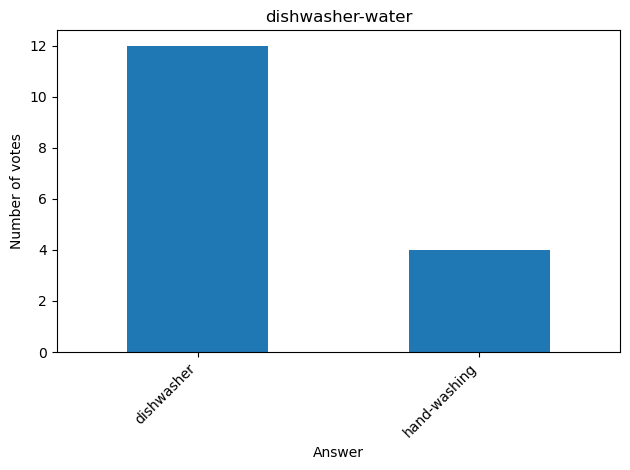

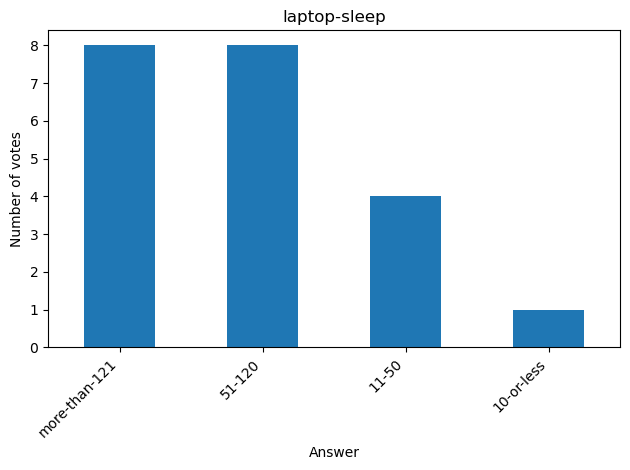

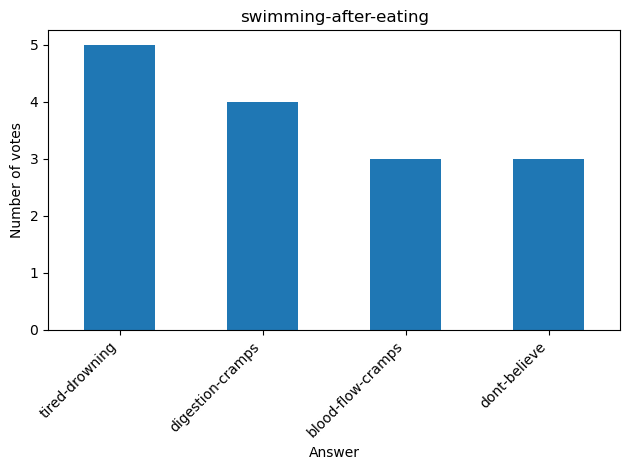

In [13]:
for poll in df["poll_id"].unique():
    poll_data = df[df["poll_id"] == poll]
    counts = poll_data["option"].value_counts()

    counts.plot(kind="bar", title=poll)
    plt.ylabel("Number of votes")
    plt.xlabel("Answer")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Everyday Data chart style

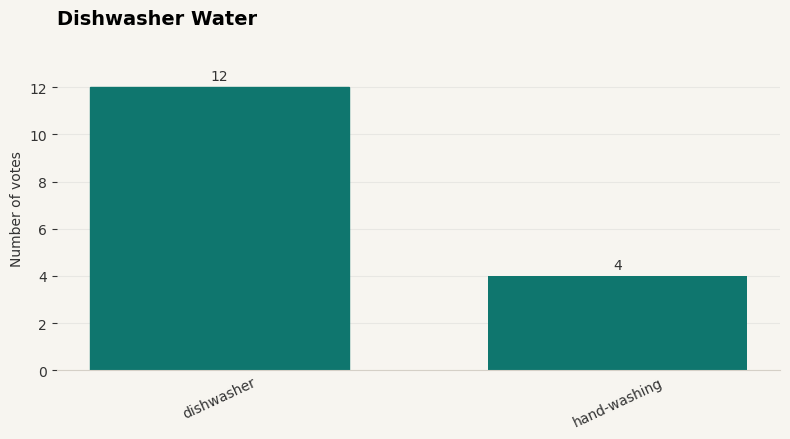

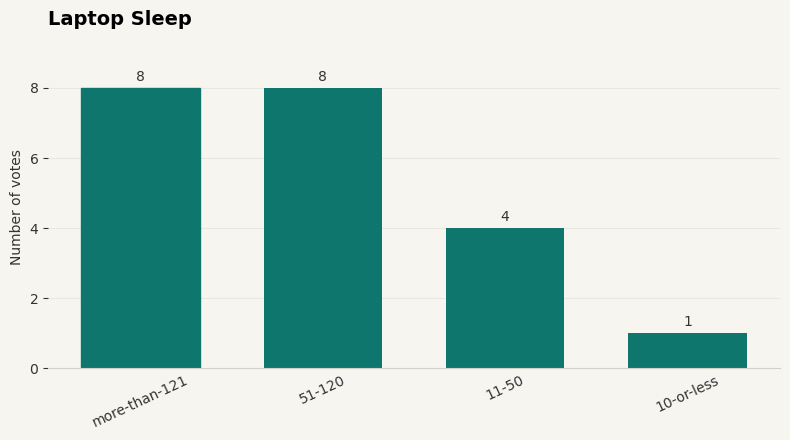

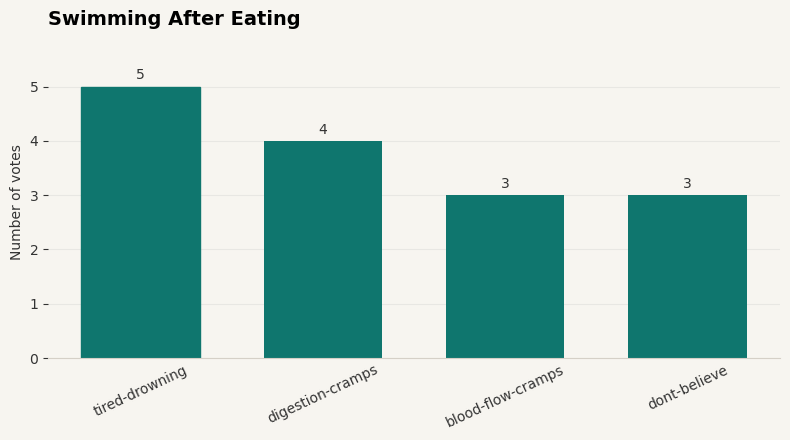

In [36]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.facecolor": "#F7F5F0",
    "axes.facecolor": "#F7F5F0",
    "axes.edgecolor": "#D5D0C7",
    "axes.labelcolor": "#333333",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
})

# colors
green = "#0F766E"
dark = "#333333"

for poll in df["poll_id"].unique():
    poll_data = df[df["poll_id"] == poll]
    counts = poll_data["option"].value_counts()

    fig, ax = plt.subplots(figsize=(8, 4.5))

    bars = ax.bar(
        counts.index,
        counts.values,
        color=green,
        width=0.65
    )

    bars[counts.values.argmax()].set_color(green)

    ax.set_title(poll.replace("-", " ").title(), loc="left", pad=15)
    ax.set_ylabel("Number of votes")
    ax.set_xlabel("")
    ax.bar_label(bars, padding=3, color=dark)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=25, length=0)
    ax.margins(y=0.15)

    plt.tight_layout()
    plt.show()

### Graph with precentage

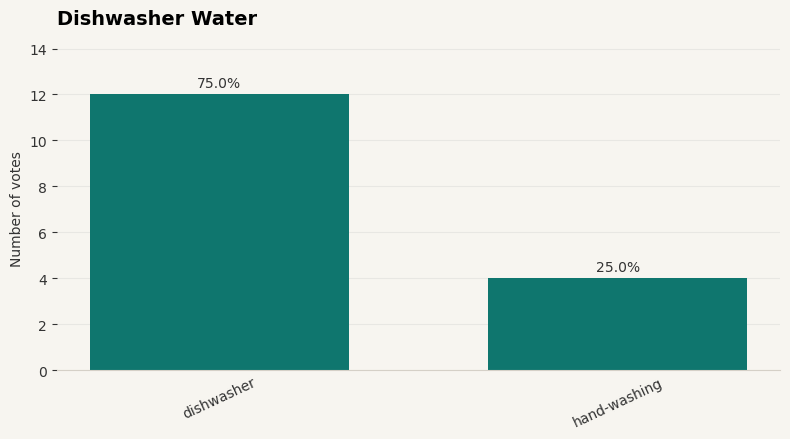

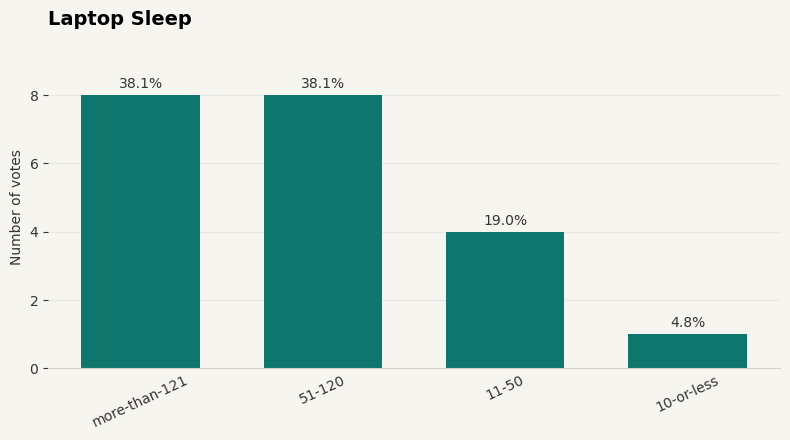

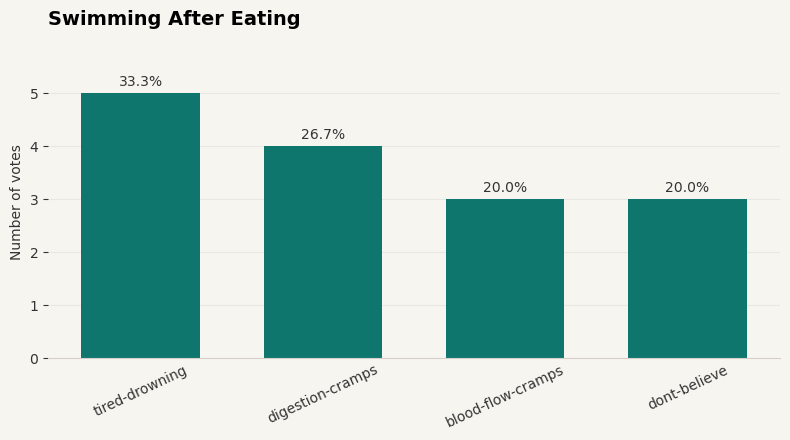

In [38]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.facecolor": "#F7F5F0",
    "axes.facecolor": "#F7F5F0",
    "axes.edgecolor": "#D5D0C7",
    "axes.labelcolor": "#333333",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
})

# colors
green = "#0F766E"
dark = "#333333"

for poll in df["poll_id"].unique():
    poll_data = df[df["poll_id"] == poll]
    counts = poll_data["option"].value_counts()
    percentages = (counts / len(poll_data) * 100).round(1)

    fig, ax = plt.subplots(figsize=(8, 4.5))

    bars = ax.bar(
        counts.index,
        counts.values,
        color=green,
        width=0.65
    )

    ax.set_title(poll.replace("-", " ").title(), loc="left", pad=15)
    ax.set_ylabel("Number of votes")
    ax.set_xlabel("")

    # procenti
    labels = [
        f"{percent}%"
        for percent in percentages.values
    ]
    ax.bar_label(bars, labels=labels, padding=3, color=dark)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=25, length=0)
    ax.margins(y=0.18)

    plt.tight_layout()
    plt.show()